<a href="https://colab.research.google.com/github/akinlayoadeniran/marketing-analytics-ml/blob/main/akin_SQL_%2B_Python_in_Google_Colab_DuckDB_%2B_Pandas.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
%pip -q install duckdb
import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
print("DuckDB version:", duckdb.__version__)

DuckDB version: 1.3.2


In [2]:
# Fictional Nova Retail dataset — deterministic, no download required.
rng = np.random.default_rng(42)
countries = np.array(["Portugal", "Spain", "France", "Germany", "Italy", "Netherlands"])
segments = np.array(["Consumer", "Small Business", "Corporate"])
channels = np.array(["Web", "Store", "Marketplace"])
statuses = np.array(["Completed", "Returned", "Cancelled"])

n_customers = 80
customers_df = pd.DataFrame({
    "customer_id": np.arange(1, n_customers + 1),
    "customer_name": [f"Customer {i:03d}" for i in range(1, n_customers + 1)],
    "country": rng.choice(countries, n_customers, p=[0.20, 0.20, 0.16, 0.18, 0.14, 0.12]),
    "segment": rng.choice(segments, n_customers, p=[0.58, 0.27, 0.15]),
    "signup_date": pd.Timestamp("2024-01-01")
    + pd.to_timedelta(rng.integers(0, 700, n_customers), unit="D"),
})

products_df = pd.DataFrame([
    (1, "Wireless Mouse", "Electronics", 29.90),
    (2, "Mechanical Keyboard", "Electronics", 79.90),
    (3, "USB-C Hub", "Electronics", 49.50),
    (4, "Noise-Cancel Headset", "Electronics", 129.00),
    (5, "Desk Lamp", "Office", 35.00),
    (6, "Notebook Pack", "Office", 14.50),
    (7, "Ergonomic Chair", "Office", 219.00),
    (8, "Standing Desk", "Office", 399.00),
    (9, "Coffee Grinder", "Home", 59.00),
    (10, "Smart Kettle", "Home", 74.00),
    (11, "Storage Box Set", "Home", 28.00),
    (12, "Air Purifier", "Home", 189.00),
    (13, "Yoga Mat", "Sports", 32.00),
    (14, "Resistance Bands", "Sports", 24.00),
    (15, "Running Belt", "Sports", 27.50),
    (16, "Fitness Tracker", "Sports", 99.00),
], columns=["product_id", "product_name", "category", "unit_price"])

n_orders = 260
orders_df = pd.DataFrame({
    "order_id": np.arange(1001, 1001 + n_orders),
    "customer_id": rng.integers(1, n_customers + 1, n_orders),
    "order_date": pd.Timestamp("2026-01-01")
    + pd.to_timedelta(rng.integers(0, 243, n_orders), unit="D"),
    "channel": rng.choice(channels, n_orders, p=[0.56, 0.29, 0.15]),
    "status": rng.choice(statuses, n_orders, p=[0.84, 0.09, 0.07]),
})

rows = []
for order_id in orders_df["order_id"]:
    n_lines = int(rng.integers(1, 5))
    product_ids = rng.choice(products_df["product_id"].to_numpy(), size=n_lines, replace=False)
    for product_id in product_ids:
        rows.append({
            "order_id": int(order_id),
            "product_id": int(product_id),
            "quantity": int(rng.integers(1, 5)),
            "discount_pct": float(
                rng.choice([0.00, 0.05, 0.10, 0.15], p=[0.55, 0.22, 0.17, 0.06])
            ),
        })
order_items_df = pd.DataFrame(rows)

for name, df in {
    "customers": customers_df,
    "products": products_df,
    "orders": orders_df,
    "order_items": order_items_df,
}.items():
    print(f"{name:12s}: {len(df):4d} rows")

customers   :   80 rows
products    :   16 rows
orders      :  260 rows
order_items :  623 rows


In [3]:

con = duckdb.connect(":memory:")
frames = {
    "customers": customers_df,
    "products": products_df,
    "orders": orders_df,
    "order_items": order_items_df,
}
for table_name, frame in frames.items():
    con.register(f"{table_name}_df", frame)
    con.execute(
        f"CREATE OR REPLACE TABLE {table_name} AS SELECT * FROM {table_name}_df"
    )
con.execute("SHOW TABLES").df()

,name
0,customers
1,customers_df
2,order_items
3,order_items_df
4,orders
5,orders_df
6,products
7,products_df


#Exercise 1

In [4]:
con.execute("SELECT COUNT(*) AS rows FROM customers").df()

,rows
0,80


In [5]:
con.execute("""
SELECT 'customers' AS table_name, COUNT(*) AS rows FROM customers
UNION ALL
SELECT 'products' AS table_name, COUNT(*) AS rows FROM products
""").df()

,table_name,rows
0,customers,80
1,products,16


In [6]:
con.execute("""
SELECT 'customers' AS table_name, COUNT(*) AS rows FROM customers
UNION ALL
SELECT 'products' AS table_name, COUNT(*) AS rows FROM products
UNION ALL
SELECT 'orders' AS table_name, COUNT(*) AS rows FROM orders
UNION ALL
SELECT 'order_items' AS table_name, COUNT(*) AS rows FROM order_items
""").df()

,table_name,rows
0,customers,80
1,products,16
2,orders,260
3,order_items,623


#Exercise 2


In [7]:

con.execute("""
SELECT order_id, customer_id, order_date, channel
FROM orders
WHERE status = 'Completed' AND order_date >= '2026-06-01'
ORDER BY order_date, order_id
""").df()

,order_id,customer_id,order_date,channel
0,1015,2,2026-06-01,Web
1,1165,72,2026-06-01,Marketplace
2,1220,12,2026-06-03,Web
3,1013,23,2026-06-04,Web
4,1122,12,2026-06-04,Web
...,...,...,...,...
83,1234,31,2026-08-27,Web
84,1112,60,2026-08-28,Store
85,1031,7,2026-08-31,Store
86,1150,55,2026-08-31,Web


#Exercise 3


In [8]:

category = "Electronics"
min_price = 50

con.execute("""
SELECT *
FROM products
WHERE category = ? AND unit_price >= ?
""", [category, min_price]).df()

,product_id,product_name,category,unit_price
0,2,Mechanical Keyboard,Electronics,79.90
1,4,Noise-Cancel Headset,Electronics,129.00


#Exercise 4

In [9]:
con.execute("""
SELECT c.country, o.order_id, o.status, p.unit_price, oi.quantity, oi.discount_pct
FROM customers c
JOIN orders o ON o.customer_id = c.customer_id
JOIN order_items oi ON oi.order_id = o.order_id
JOIN products p ON p.product_id = oi.product_id
LIMIT 5
""").df()

,country,order_id,status,unit_price,quantity,discount_pct
0,Italy,1001,Completed,24.00,4,0.10
1,Italy,1001,Completed,32.00,1,0.00
2,Italy,1001,Completed,79.90,3,0.00
3,Italy,1001,Completed,27.50,1,0.10
4,Germany,1002,Completed,59.00,4,0.10


In [10]:

con.execute("""
SELECT c.country,
       COUNT(DISTINCT o.order_id) AS completed_orders,
       SUM(p.unit_price * oi.quantity * (1 - oi.discount_pct)) AS net_revenue
FROM customers c
JOIN orders o ON o.customer_id = c.customer_id
JOIN order_items oi ON oi.order_id = o.order_id
JOIN products p ON p.product_id = oi.product_id
WHERE o.status = 'Completed'
GROUP BY c.country
ORDER BY net_revenue DESC
""").df()

,country,completed_orders,net_revenue
0,France,42,"24,696.61"
1,Portugal,39,"24,506.74"
2,Germany,39,"21,922.34"
3,Italy,36,"21,526.22"
4,Spain,41,"19,884.67"
5,Netherlands,16,"9,432.45"


#Exercise 5

In [11]:
# Exercise 5A
monthly_category = con.execute("""
SELECT DATE_TRUNC('month', o.order_date) AS month,
       p.category,
       SUM(p.unit_price * oi.quantity * (1 - oi.discount_pct)) AS net_revenue
FROM orders o
JOIN order_items oi ON oi.order_id = o.order_id
JOIN products p ON p.product_id = oi.product_id
WHERE o.status = 'Completed'
GROUP BY month, p.category
ORDER BY month, p.category
""").df()

monthly_category.head()

,month,category,net_revenue
0,2026-01-01,Electronics,"6,698.05"
1,2026-01-01,Home,"6,644.75"
2,2026-01-01,Office,"10,969.20"
3,2026-01-01,Sports,"1,846.30"
4,2026-02-01,Electronics,"2,611.91"


In [12]:
# Exercise 5B
pivot = monthly_category.pivot(index='month', columns='category', values='net_revenue')
pivot

category,Electronics,Home,Office,Sports
month,,,,
2026-01-01,"6,698.05","6,644.75","10,969.20","1,846.30"
2026-02-01,"2,611.91","1,744.00","7,299.35","1,335.05"
2026-03-01,"1,686.16",647.60,"4,981.85","1,270.45"
2026-04-01,"3,734.72","2,100.45","3,649.40","2,276.25"
2026-05-01,"1,829.67","3,368.05","5,766.60","1,874.27"
2026-06-01,"3,377.86","5,653.35","6,998.05","2,026.90"
2026-07-01,"2,110.17","2,506.20","6,397.25","2,123.08"
2026-08-01,"3,194.32","3,942.70","9,497.10","1,807.97"


#Exercise 6

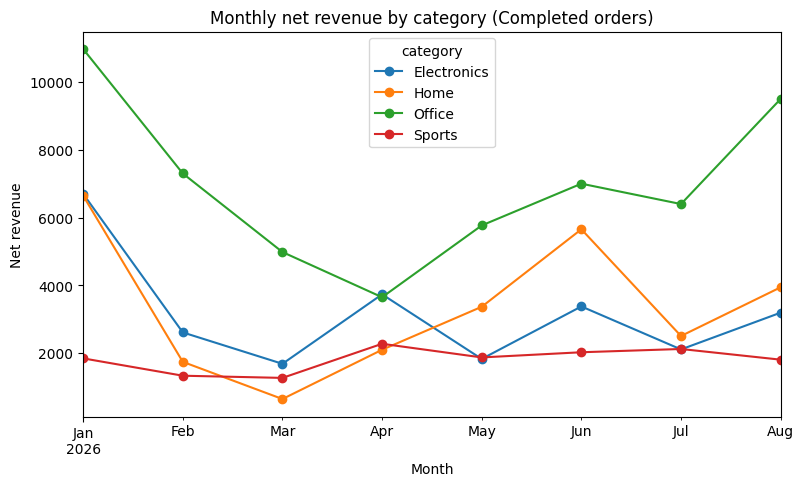

In [13]:
# Exercise 6
ax = pivot.plot(kind='line', marker='o', figsize=(9, 5))
ax.set_title('Monthly net revenue by category (Completed orders)')
ax.set_xlabel('Month')
ax.set_ylabel('Net revenue')
plt.show()

#Exercise 7

In [14]:
# Exercise 7 - step 1 (just the CTE)
con.execute("""
WITH customer_revenue AS (
    SELECT c.customer_id, c.customer_name, c.country,
           SUM(p.unit_price * oi.quantity * (1 - oi.discount_pct)) AS net_revenue
    FROM customers c
    JOIN orders o ON o.customer_id = c.customer_id
    JOIN order_items oi ON oi.order_id = o.order_id
    JOIN products p ON p.product_id = oi.product_id
    WHERE o.status = 'Completed'
    GROUP BY c.customer_id, c.customer_name, c.country
)
SELECT * FROM customer_revenue
ORDER BY country, net_revenue DESC
""").df()

,customer_id,customer_name,country,net_revenue
0,35,Customer 035,France,"4,268.59"
1,70,Customer 070,France,"3,535.01"
2,2,Customer 002,France,"3,348.03"
3,15,Customer 015,France,"2,688.64"
4,38,Customer 038,France,"2,071.90"
...,...,...,...,...
69,71,Customer 071,Spain,713.85
70,16,Customer 016,Spain,590.20
71,22,Customer 022,Spain,540.40
72,44,Customer 044,Spain,106.81


In [15]:
# Exercise 7
con.execute("""
WITH customer_revenue AS (
    SELECT c.customer_id, c.customer_name, c.country,
           SUM(p.unit_price * oi.quantity * (1 - oi.discount_pct)) AS net_revenue
    FROM customers c
    JOIN orders o ON o.customer_id = c.customer_id
    JOIN order_items oi ON oi.order_id = o.order_id
    JOIN products p ON p.product_id = oi.product_id
    WHERE o.status = 'Completed'
    GROUP BY c.customer_id, c.customer_name, c.country
),
ranked AS (
    SELECT country, customer_name, net_revenue,
           ROW_NUMBER() OVER (PARTITION BY country ORDER BY net_revenue DESC) AS country_rank
    FROM customer_revenue
)
SELECT country, country_rank, customer_name, net_revenue
FROM ranked
WHERE country_rank <= 3
ORDER BY country, country_rank
""").df()

,country,country_rank,customer_name,net_revenue
0,France,1,Customer 035,"4,268.59"
1,France,2,Customer 070,"3,535.01"
2,France,3,Customer 002,"3,348.03"
3,Germany,1,Customer 043,"6,689.66"
4,Germany,2,Customer 004,"1,853.50"
5,Germany,3,Customer 013,"1,844.80"
6,Italy,1,Customer 019,"4,876.45"
7,Italy,2,Customer 014,"3,223.65"
8,Italy,3,Customer 031,"2,419.93"
9,Netherlands,1,Customer 012,"3,567.50"


In [17]:
# Final challenge
con.execute("""
WITH category_revenue AS (
    SELECT c.country, p.category,
           SUM(p.unit_price * oi.quantity * (1 - oi.discount_pct)) AS net_revenue
    FROM customers c
    JOIN orders o ON o.customer_id = c.customer_id
    JOIN order_items oi ON oi.order_id = o.order_id
    JOIN products p ON p.product_id = oi.product_id
    WHERE o.status = 'Completed'
    GROUP BY c.country, p.category
),
ranked AS (
    SELECT country, category, net_revenue,
           RANK() OVER (PARTITION BY country ORDER BY net_revenue DESC) AS category_rank
    FROM category_revenue
)
SELECT country, category, net_revenue
FROM ranked
WHERE category_rank = 1
ORDER BY country
""").df()

,country,category,net_revenue
0,France,Office,"9,340.73"
1,Germany,Office,"12,240.67"
2,Italy,Office,"8,689.58"
3,Netherlands,Office,"4,100.40"
4,Portugal,Office,"11,921.65"
5,Spain,Office,"9,265.77"


In every country, the highest-revenue category is Office. It earns the most in Germany (12,240.68) and the least in the Netherlands (4,100.40). One idea for the company is to focus more on Office products in Germany, because Germany has the highest Office revenue.